# 5. A net-pay decision and maximum-likelihood variograms

Notebooks 1-4 found that the variogram type barely changes the decision. Two features of that design could have hidden
an effect, so they are tested here as a pre-registered experiment on 400 fresh truth models (`netpay/`):

1. **The decisions were sums of OOIP**, for which the smooth kriged map is already close to the best answer. Here only
   rock above a **net-pay cutoff** counts (the best 30% of each scenario's porosity distribution). A smoothed map
   misjudges how much rock passes a cutoff. The alternative is the **expected net OOIP**: the cutoff applied to each
   cell's local uncertainty distribution, which is what averaging many SGS realizations converges to.
2. **Every variogram type went through the same automatic fit.** Two alternatives separate type from fitting: the
   semivariogram with **resolvability constraints** (no range below the well spacing, anisotropy at most 5:1), and
   **maximum likelihood**, which infers the model directly from the wells, with no experimental variogram.

The 13 hypotheses, sample size and decision rule were committed in `netpay/hypotheses.json` before any data on the test
seed existed. Verdicts: CONFIRMED / REVERSED (significant after Holm correction), EQUIVALENT (90% CI inside
+/- $0.25MM, or +/- 5 points for the OOIP error), INCONCLUSIVE.

In [1]:
import warnings, sys, json; warnings.filterwarnings('ignore')
sys.path.insert(0, 'netpay')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import core
from vstudy import config as C, plots, wells as W, kriging, decisions as D, fitting
from vstudy.simulate import make_truth
from vstudy.variography import experimental
pd.set_option('display.precision', 3); pd.set_option('display.width', 180)
hyp = json.load(open('netpay/hypotheses.json'))
T = pd.read_csv('netpay/results/hypothesis_tests.csv', index_col=0)
d = pd.read_csv('netpay/results/decisions.csv'); f = pd.read_csv('netpay/results/fits.csv')
d['net_err_pct'] = 100 * (d.field_net - d.true_field_net) / d.true_field_net
ORDER = [m for m in hyp['method_order'] if m in d.method.unique()]
LAB = dict(C.LABEL, semivariogram_c='Semivariogram, constrained fit', ml='Maximum likelihood')

## What the cutoff does to a kriged map

One dataset with 50 random wells, chosen by rule as the one whose regret difference between the two decisions is
closest to the average difference over all such datasets (a typical case, not the most favourable). Left: the true net pay (rock above the cutoff). Middle:
the kriged map with the cutoff applied; smoothing removes most of the high-porosity rock. Right: the expected net OOIP,
which keeps partial credit where the rock *might* pass the cutoff. Circles: the 3 wells each map would drill; stars: the
best 3 wells on the truth.

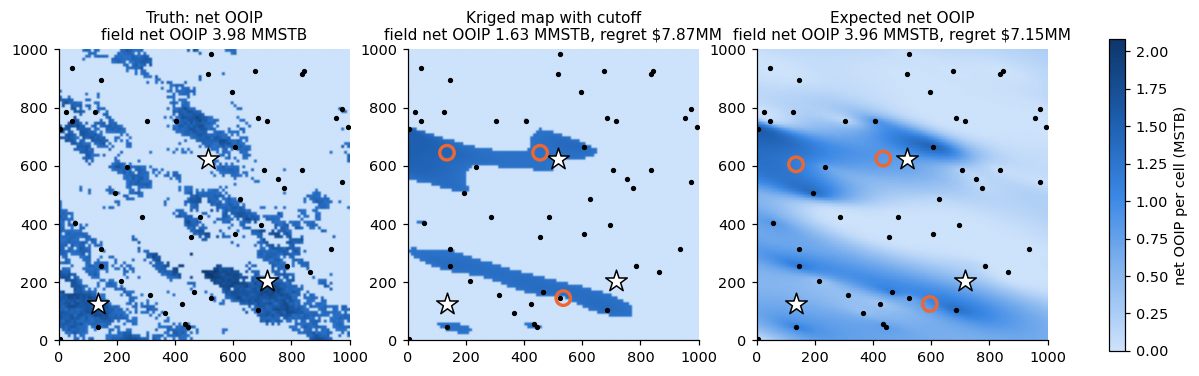

facies scenario, truth 5; cutoff porosity 0.210; true net fraction 27%; kriged-map net fraction 12%


In [2]:
q = d[(d.method == 'semivariogram') & (d.n_wells == 50) & (d.design == 'random')].pivot_table(index=['scenario', 'realization'], columns='rule', values='regret_MM')
gap = q.etype_net - q.map_net
scen, real = (gap - gap.mean()).abs().idxmin()
seed = hyp['seed']; si = C.SCEN_NAMES.index(scen)
phi, _ = make_truth(scen, np.random.default_rng([seed, si, real])); c = core.cutoff(scen)
w = W.sample(phi, 'random', 50, np.random.default_rng([seed, si, real, 50, 0, 1]))
wt = W.decluster(w['x'], w['y'], w['v']); ns = W.NormalScore(w['v'], wt)
m = fitting.fit_all(experimental(w['x'], w['y'], w['v'], ns.scores))['semivariogram']
est = kriging.ordinary_kriging(w['x'], w['y'], w['v'], m, 1.0)[0]
maps = {'Truth: net OOIP': core.net_cells(phi, c), 'Kriged map with cutoff': core.net_cells(est, c),
        'Expected net OOIP': core.etype_net(w['x'], w['y'], ns, m, c)}
dv_true = D.drainage_from_ooip(maps['Truth: net OOIP']); opt = D.place(dv_true, 'swap')
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))
for ax, (name, a) in zip(axes, maps.items()):
    im = ax.imshow(a / 1e3, extent=plots.EXTENT, cmap=plots.SEQ, vmin=0, vmax=maps['Truth: net OOIP'].max() / 1e3)
    s = D.place(D.drainage_from_ooip(a), 'swap')
    ax.scatter(D.CX[opt], D.CY[opt], marker='*', s=220, c='white', edgecolors='black', zorder=4)
    if name != 'Truth: net OOIP':
        ax.scatter(D.CX[s], D.CY[s], s=90, facecolors='none', edgecolors=plots.C_MIN, linewidths=2.2, zorder=5)
    ax.scatter(w['x'], w['y'], s=6, c='black')
    reg = C.to_money(D.program_value(opt, dv_true) - D.program_value(s, dv_true))
    ax.set_title(f"{name}\nfield net OOIP {a.sum() / 1e6:.2f} MMSTB" + ('' if name.startswith('Truth') else f', regret ${reg:.2f}MM'), fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label='net OOIP per cell (MSTB)'); plt.show()
print(f'{scen} scenario, truth {real}; cutoff porosity {c:.3f}; true net fraction {(phi >= c).mean():.0%}; kriged-map net fraction {(est >= c).mean():.0%}')

## The pre-registered tests

Differences are A minus B (negative = A better), averaged within each truth model over the three well counts and both
well designs; 400 truth models.

,claim,mean_diff,ci95_lo,ci95_hi,p_holm,pct_truths_better,verdict
id,,,,,,,
H1,"With a net-pay cutoff, deciding on the expected net OOIP beats deciding on the smooth kriged map",-0.515,-0.595,-0.435,0.000,73,CONFIRMED
H2,The expected net OOIP estimates field net OOIP better than the kriged map with the cutoff applied,-15.068,-16.355,-13.781,0.000,88,CONFIRMED
H3,Maximum-likelihood variogram beats the fitted semivariogram (original decision),+0.031,-0.036,+0.097,1.000,53,EQUIVALENT
H4,Maximum-likelihood variogram beats the fitted semivariogram (net-pay decision),-0.093,-0.191,+0.005,0.505,56,EQUIVALENT
H5,"Constraining the fit (minimum range, anisotropy cap) beats the unconstrained fit",-0.032,-0.055,-0.010,0.046,53,CONFIRMED
H6,Kriging with the constrained fit beats inverse distance,+0.114,+0.060,+0.168,0.000,44,REVERSED
H7,Correlogram differs from the semivariogram under the net-pay decision,-0.050,-0.130,+0.031,1.000,51,EQUIVALENT
H8,General relative differs from the semivariogram under the net-pay decision,-0.021,-0.078,+0.037,1.000,55,EQUIVALENT
H9,Pairwise relative differs from the semivariogram under the net-pay decision,+0.010,-0.054,+0.074,1.000,52,EQUIVALENT


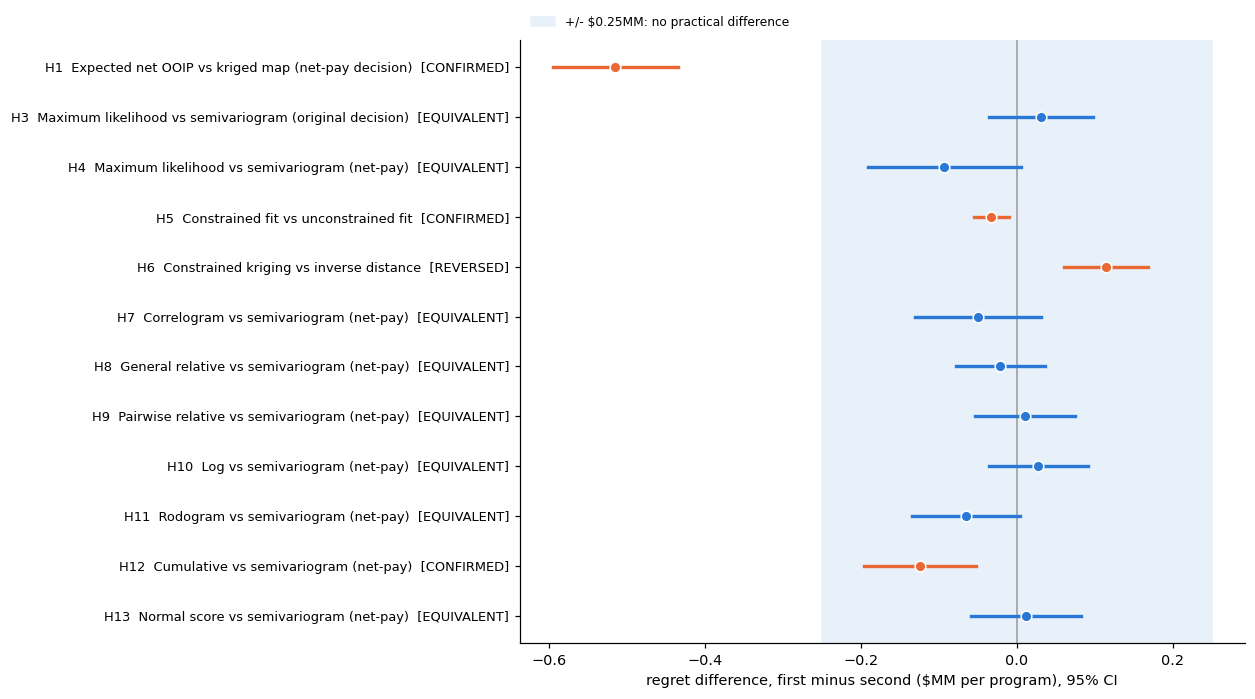

In [3]:
show = T[['claim', 'mean_diff', 'ci95_lo', 'ci95_hi', 'p_holm', 'pct_truths_better', 'verdict']]
display(show.style.format({'mean_diff': '{:+.3f}', 'ci95_lo': '{:+.3f}', 'ci95_hi': '{:+.3f}', 'p_holm': '{:.3f}', 'pct_truths_better': '{:.0f}'}))
R = T[T.metric == 'regret_MM']
SHORT = {'H1': 'Expected net OOIP vs kriged map (net-pay decision)', 'H3': 'Maximum likelihood vs semivariogram (original decision)',
         'H4': 'Maximum likelihood vs semivariogram (net-pay)', 'H5': 'Constrained fit vs unconstrained fit',
         'H6': 'Constrained kriging vs inverse distance', 'H7': 'Correlogram vs semivariogram (net-pay)',
         'H8': 'General relative vs semivariogram (net-pay)', 'H9': 'Pairwise relative vs semivariogram (net-pay)',
         'H10': 'Log vs semivariogram (net-pay)', 'H11': 'Rodogram vs semivariogram (net-pay)',
         'H12': 'Cumulative vs semivariogram (net-pay)', 'H13': 'Normal score vs semivariogram (net-pay)'}
fig, ax = plt.subplots(figsize=(11.5, 0.42 * len(R) + 1.4))
y = np.arange(len(R))[::-1]
ax.axvspan(-0.25, 0.25, color='#e8f0fa', label='+/- $0.25MM: no practical difference')
ax.axvline(0, color=plots.C_MUTED, lw=1)
for yi, (hid, r) in zip(y, R.iterrows()):
    col = plots.C_MIN if r.verdict in ('CONFIRMED', 'REVERSED') else plots.C_MAJ
    ax.plot([r.ci95_lo, r.ci95_hi], [yi, yi], color=col, lw=2.2); ax.plot(r.mean_diff, yi, 'o', color=col, mec='white', ms=7)
ax.set_yticks(y); ax.set_yticklabels([f'{h}  {SHORT[h]}  [{r.verdict}]' for h, r in R.iterrows()], fontsize=8.5)
ax.set_xlabel('regret difference, first minus second ($MM per program), 95% CI'); ax.legend(frameon=False, fontsize=8, loc='lower left', bbox_to_anchor=(0, 1))
plt.tight_layout(); plt.show()

## Smoothing and the field net OOIP

Signed error of the estimated field net OOIP (%), semivariogram model. The kriged map with the cutoff applied loses
net pay because smoothing pulls high porosity toward the mean. The expected-value estimate removes that, but inherits
the sampling bias of preferential (sweet-spot) wells. `sgs_net` is the same estimate from 50 SGS realizations (50 wells).

In [4]:
s = d[d.method == 'semivariogram']
display(s.pivot_table(index='rule', columns=['design', 'n_wells'], values='net_err_pct').loc[['map_net', 'etype_net', 'sgs_net']].round(0))
g = d[d.rule == 'sgs_net']
print('True field net OOIP inside the SGS P10-P90 (ideal 80%):', (100 * g.assign(inside=g.net_inside_p10_p90.astype(float)).groupby('design').inside.mean()).round(0).to_dict())

design    preferential             random            
n_wells            25    50    100    25    50    100
rule                                                 
map_net           16.0   3.0  -0.0  -58.0 -44.0 -34.0
etype_net         45.0  40.0  34.0   -1.0  -1.0   0.0
sgs_net            NaN  39.0   NaN    NaN  -1.0   NaN

True field net OOIP inside the SGS P10-P90 (ideal 80%): {'preferential': 14.0, 'random': 56.0}


## Does a better fitting method recover the variogram?

Azimuth error (anisotropic and facies scenarios) and short-range RMSE against the exhaustive truth variogram, by well
count. `truth_variogram` is the model fitted to the complete truth: the floor.

azi_err                 vario_rmse              
n_wells                            25      50      100        25     50     100
Semivariogram                   35.725  27.950  21.000      0.277  0.193  0.145
Semivariogram, constrained fit  35.725  27.950  21.000      0.246  0.179  0.142
Maximum likelihood              32.998  20.526  11.366      0.225  0.167  0.130
Correlogram                     36.825  28.050  20.100      0.270  0.190  0.147
General relative                36.525  27.375  20.875      0.276  0.192  0.145
Pairwise relative               36.000  27.075  20.375      0.275  0.190  0.143
Log semivariogram               36.400  27.100  20.675      0.278  0.193  0.145
Rodogram                        36.250  27.450  20.750      0.274  0.205  0.160
Cumulative                      35.300  27.075  17.975      0.291  0.199  0.147
Normal-score semivariogram      36.900  28.875  21.425      0.268  0.191  0.147
True variogram                   9.700   9.700   9.700      0.077  0.077  0.077

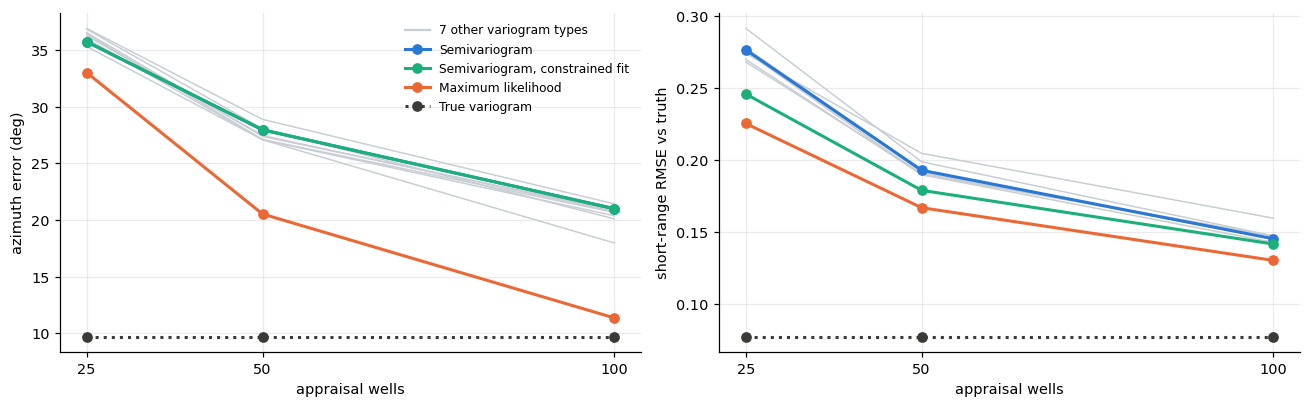

In [5]:
acc = f.pivot_table(index='method', columns='n_wells', values=['azi_err', 'vario_rmse']).reindex(ORDER[:-1])
acc.index = [LAB.get(i, i) for i in acc.index]
display(acc.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, yl in zip(axes, ('azi_err', 'vario_rmse'), ('azimuth error (deg)', 'short-range RMSE vs truth')):
    t = f.pivot_table(index='n_wells', columns='method', values=col)
    for mth in C.VTYPES[1:]:
        ax.plot(t.index, t[mth], color='#c9ced4', lw=1)
    ax.plot([], [], color='#c9ced4', label='7 other variogram types')
    for mth, cl, ls in (('semivariogram', plots.C_MAJ, '-'), ('semivariogram_c', '#1baf7a', '-'), ('ml', plots.C_MIN, '-'), ('truth_variogram', plots.C_TRUTH, ':')):
        ax.plot(t.index, t[mth], ls, marker='o', color=cl, lw=2, label=LAB[mth])
    ax.set_xticks(C.WELL_COUNTS); ax.set_xlabel('appraisal wells'); ax.set_ylabel(yl); ax.grid(alpha=0.25)
axes[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

## Regret by method, rule and well count

`map_total`: the main study's decision (all OOIP, kriged map). `map_net` and `etype_net`: the net-pay decision made on
the kriged map and on the expected net OOIP. $MM per 3-well program.

In [6]:
reg = d[d.rule != 'sgs_net'].pivot_table(index='method', columns=['rule', 'n_wells'], values='regret_MM').reindex(ORDER)
reg.index = [LAB.get(i, i) for i in reg.index]
display(reg.round(2))
by = d[(d.method == 'semivariogram') & d.rule.isin(['map_net', 'etype_net'])].pivot_table(index='scenario', columns='rule', values='regret_MM')
by['etype minus map'] = by.etype_net - by.map_net
by.round(2)

rule                            etype_net             map_net             map_total            
n_wells                               25    50    100     25    50    100       25    50    100
Semivariogram                        5.22  3.42  2.00    5.89  3.93  2.37      3.02  1.90  1.11
Semivariogram, constrained fit       5.10  3.33  1.97    5.73  3.82  2.32      2.95  1.89  1.09
Maximum likelihood                   5.46  3.26  1.64    6.00  3.61  1.91      3.24  1.90  0.98
Correlogram                          5.22  3.33  1.94    5.86  3.74  2.30      3.03  1.88  1.12
General relative                     5.18  3.41  1.99    5.96  3.76  2.26      3.04  1.90  1.10
Pairwise relative                    5.28  3.37  2.02    6.04  3.83  2.29      3.08  1.95  1.09
Log semivariogram                    5.31  3.41  2.01    6.04  3.84  2.25      3.09  1.94  1.10
Rodogram                             5.14  3.30  2.01    5.96  3.66  2.29      3.03  1.89  1.11
Cumulative                           5.24  3.26  1.76    6.06  3.72  2.01      3.07  1.82  0.98
Normal-score semivariogram           5.24  3.36  2.07    6.01  3.85  2.24      3.03  1.95  1.12
True variogram                       4.26  2.78  1.61    4.93  3.12  1.88      2.33  1.53  0.91
Inverse distance (no variogram)       NaN   NaN   NaN    5.61  3.77  2.43      2.74  1.79  1.06

rule,etype_net,map_net,etype minus map
scenario,,,
anisotropic,3.01,3.52,-0.51
facies,4.06,4.88,-0.82
gaussian,3.05,3.50,-0.45
skewed,4.06,4.34,-0.28


## By well count (exploratory, not pre-registered)

The pre-registered tests pool the three well counts. Split by well count, the inference method shows a crossover: with
few wells the simple fit is safer, with many wells methods that use the data more fully pull ahead. Differences in $MM
with 95% CIs across the 400 truth models; treat as a lead for future tests, not a confirmed result.

In [7]:
from scipy import stats as st
def diff(a, b, n):
    q = d[d.n_wells == n]
    g = lambda s: q[(q.method == s[0]) & (q.rule == s[1])].groupby(['scenario', 'realization']).regret_MM.mean()
    x = (g(a) - g(b)).dropna(); h = st.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return f'{x.mean():+.2f} [{x.mean() - h:+.2f}, {x.mean() + h:+.2f}]'
rows = {'Expected net OOIP vs kriged map (semivariogram, net-pay)': (('semivariogram', 'etype_net'), ('semivariogram', 'map_net')),
        'Maximum likelihood vs semivariogram (original decision)': (('ml', 'map_total'), ('semivariogram', 'map_total')),
        'Maximum likelihood vs semivariogram (net-pay)': (('ml', 'etype_net'), ('semivariogram', 'etype_net')),
        'Cumulative vs semivariogram (net-pay)': (('cumulative', 'etype_net'), ('semivariogram', 'etype_net')),
        'True variogram vs semivariogram (net-pay)': (('truth_variogram', 'etype_net'), ('semivariogram', 'etype_net')),
        'Constrained kriging vs inverse distance (original decision)': (('semivariogram_c', 'map_total'), ('idw', 'map_total')),
        'Maximum likelihood kriging vs inverse distance (original decision)': (('ml', 'map_total'), ('idw', 'map_total'))}
pd.DataFrame({k: {f'{n} wells': diff(a, b, n) for n in C.WELL_COUNTS} for k, (a, b) in rows.items()}).T

,25 wells,50 wells,100 wells
"Expected net OOIP vs kriged map (semivariogram, net-pay)","-0.67 [-0.84, -0.50]","-0.50 [-0.63, -0.38]","-0.37 [-0.47, -0.27]"
Maximum likelihood vs semivariogram (original decision),"+0.22 [+0.08, +0.37]","-0.01 [-0.10, +0.09]","-0.12 [-0.19, -0.06]"
Maximum likelihood vs semivariogram (net-pay),"+0.24 [+0.03, +0.46]","-0.16 [-0.31, -0.02]","-0.36 [-0.45, -0.26]"
Cumulative vs semivariogram (net-pay),"+0.03 [-0.12, +0.17]","-0.16 [-0.29, -0.04]","-0.24 [-0.33, -0.15]"
True variogram vs semivariogram (net-pay),"-0.95 [-1.14, -0.77]","-0.65 [-0.79, -0.50]","-0.39 [-0.49, -0.28]"
Constrained kriging vs inverse distance (original decision),"+0.21 [+0.10, +0.33]","+0.10 [+0.02, +0.19]","+0.03 [-0.04, +0.09]"
Maximum likelihood kriging vs inverse distance (original decision),"+0.50 [+0.36, +0.65]","+0.11 [+0.02, +0.20]","-0.08 [-0.15, -0.02]"


## Summary

In [8]:
v = lambda h: f"{T.loc[h, 'mean_diff']:+.2f} [{T.loc[h, 'ci95_lo']:+.2f}, {T.loc[h, 'ci95_hi']:+.2f}] {T.loc[h, 'verdict']}"
types = T.loc[[f'H{i}' for i in range(7, 14)]]
rnd = d[(d.method == 'semivariogram') & (d.design == 'random')].groupby('rule').net_err_pct.mean()
az = f.pivot_table(index='method', columns='n_wells', values='azi_err')
print(f"Net-pay decision, expected net OOIP vs kriged map (H1): {v('H1')} $MM")
print(f"Field net OOIP error, expected value vs kriged map (H2): {v('H2')} points; with random wells the kriged map is off by {rnd['map_net']:+.0f}%, the expected value by {rnd['etype_net']:+.0f}%")
print(f"Maximum likelihood vs semivariogram: original decision (H3) {v('H3')}; net-pay decision (H4) {v('H4')} $MM")
print(f"  azimuth error at 25/50/100 wells: ML {az.loc['ml', 25]:.0f}/{az.loc['ml', 50]:.0f}/{az.loc['ml', 100]:.0f} deg, semivariogram {az.loc['semivariogram', 25]:.0f}/{az.loc['semivariogram', 50]:.0f}/{az.loc['semivariogram', 100]:.0f} deg")
print(f"Constrained fit vs unconstrained (H5): {v('H5')}; constrained kriging vs inverse distance (H6): {v('H6')} $MM")
print(f"7 variogram types vs semivariogram under the net-pay decision (H7-H13): {dict(types.verdict.value_counts())}; largest |difference| {types.mean_diff.abs().max():.2f} $MM")

Net-pay decision, expected net OOIP vs kriged map (H1): -0.51 [-0.60, -0.43] CONFIRMED $MM
Field net OOIP error, expected value vs kriged map (H2): -15.07 [-16.35, -13.78] CONFIRMED points; with random wells the kriged map is off by -45%, the expected value by -1%
Maximum likelihood vs semivariogram: original decision (H3) +0.03 [-0.04, +0.10] EQUIVALENT; net-pay decision (H4) -0.09 [-0.19, +0.01] EQUIVALENT $MM
  azimuth error at 25/50/100 wells: ML 33/21/11 deg, semivariogram 36/28/21 deg
Constrained fit vs unconstrained (H5): -0.03 [-0.06, -0.01] CONFIRMED; constrained kriging vs inverse distance (H6): +0.11 [+0.06, +0.17] REVERSED $MM
7 variogram types vs semivariogram under the net-pay decision (H7-H13): {'EQUIVALENT': np.int64(6), 'CONFIRMED': np.int64(1)}; largest |difference| 0.12 $MM
